In [1]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the customer churn dataset
df = pd.read_csv("../data/Bank_Customer_Churn_Prediction.csv")

# Display the first 5 rows
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Check the number of rows and columns
df.shape

(10000, 12)

In [4]:
# Check column data types and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  str    
 3   gender            10000 non-null  str    
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 937.6 KB


In [5]:
# Check for missing values
df.isnull().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [6]:
# Check duplicated rows
df.duplicated().sum()

np.int64(0)

In [7]:
# Check duplicated customer IDs
df["customer_id"].duplicated().sum()

np.int64(0)

In [8]:
# Check summary statistics of customer balances
df["balance"].describe()

count     10000.000000
mean      76485.889288
std       62397.405202
min           0.000000
25%           0.000000
50%       97198.540000
75%      127644.240000
max      250898.090000
Name: balance, dtype: float64

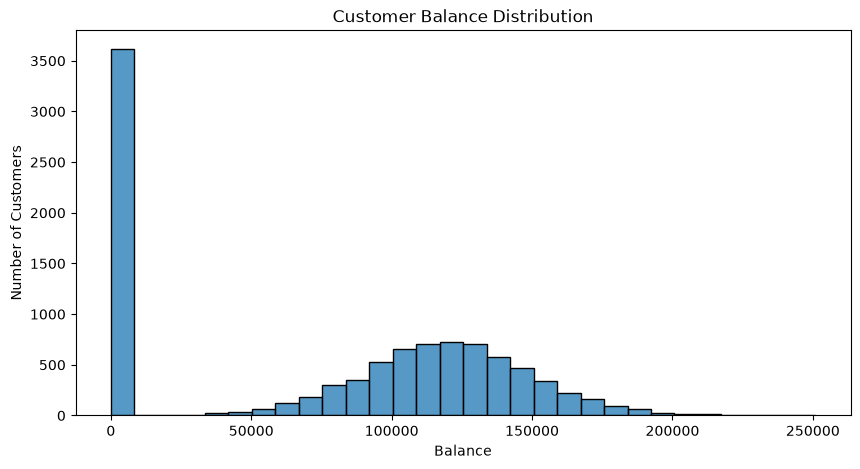

In [9]:
# Visualize the distribution of customer balances
plt.figure(figsize=(10, 5))

sns.histplot(df["balance"], bins=30)

plt.title("Customer Balance Distribution")
plt.xlabel("Balance")
plt.ylabel("Number of Customers")

plt.show()

In [10]:
# Count customers with zero balance
zero_balance_count = (df["balance"] == 0).sum()

print("Customers with zero balance:", zero_balance_count)

Customers with zero balance: 3617


In [11]:
# Create balance ranges for customer segmentation
bins = [-1, 0, 50000, 100000, 150000, 200000, np.inf]

labels = [
    "0",
    "1-50K",
    "50K-100K",
    "100K-150K",
    "150K-200K",
    "200K+"
]

df["balance_range"] = pd.cut(
    df["balance"],
    bins=bins,
    labels=labels
)

In [12]:
# Display balance and balance range columns
df[["balance", "balance_range"]].head(10)

,balance,balance_range
0,0.00,0
1,83807.86,50K-100K
2,159660.80,150K-200K
3,0.00,0
4,125510.82,100K-150K
5,113755.78,100K-150K
6,0.00,0
7,115046.74,100K-150K
8,142051.07,100K-150K
9,134603.88,100K-150K


In [13]:
# Count customers in each balance range
df["balance_range"].value_counts().sort_index()

balance_range
0            3617
1-50K          75
50K-100K     1509
100K-150K    3830
150K-200K     935
200K+          34
Name: count, dtype: int64

In [14]:
# Calculate the overall churn rate
overall_churn_rate = df["churn"].mean() * 100

print(f"Overall Churn Rate: {overall_churn_rate:.2f}%")

Overall Churn Rate: 20.37%


In [15]:
# Analyze customer churn by balance range
balance_analysis = (
    df.groupby("balance_range", observed=True)
      .agg(
          customer_count=("customer_id", "count"),
          churned_customers=("churn", "sum"),
          churn_rate=("churn", "mean")
      )
      .reset_index()
)

# Convert churn rate to percentage
balance_analysis["churn_rate"] = (
    balance_analysis["churn_rate"] * 100
).round(2)

balance_analysis

,balance_range,customer_count,churned_customers,churn_rate
0,0,3617,500,13.82
1,1-50K,75,26,34.67
2,50K-100K,1509,300,19.88
3,100K-150K,3830,987,25.77
4,150K-200K,935,205,21.93
5,200K+,34,19,55.88


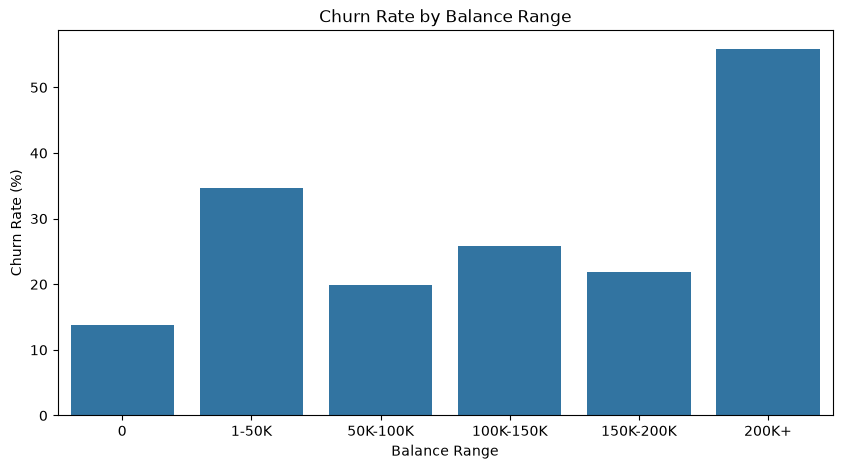

In [16]:
# Visualize churn rate by balance range
plt.figure(figsize=(10, 5))

sns.barplot(
    data=balance_analysis,
    x="balance_range",
    y="churn_rate"
)

plt.title("Churn Rate by Balance Range")
plt.xlabel("Balance Range")
plt.ylabel("Churn Rate (%)")

plt.show()

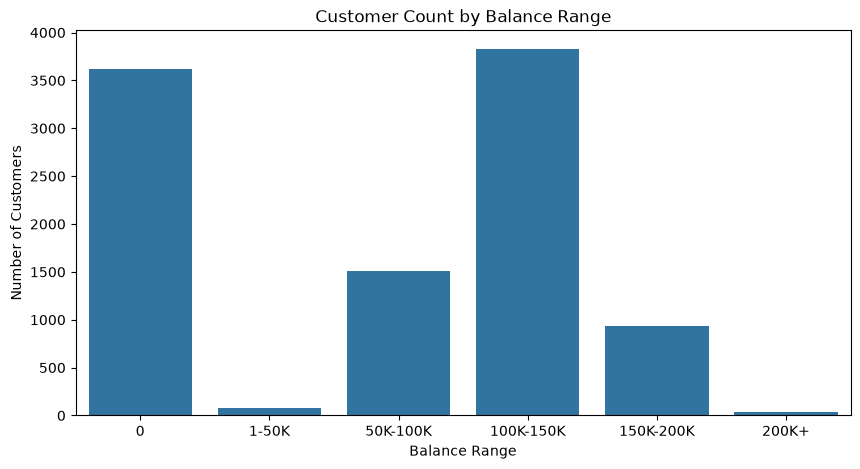

In [17]:
# Visualize customer count by balance range
plt.figure(figsize=(10, 5))

sns.barplot(
    data=balance_analysis,
    x="balance_range",
    y="customer_count"
)

plt.title("Customer Count by Balance Range")
plt.xlabel("Balance Range")
plt.ylabel("Number of Customers")

plt.show()

### Balance Range Analysis

- Customers with zero balance form a large part of the dataset.
- The 200K+ segment has the highest churn rate, but it contains only a small number of customers.
- The 100K-150K segment has a relatively high churn rate and the highest number of churned customers.
- Customer count should be considered together with churn rate when interpreting the results.

## Churn Analysis by Customer Characteristics

### Country Analysis

In [18]:
# Analyze customer churn by country
country_analysis = (
    df.groupby("country")
      .agg(
          customer_count=("customer_id", "count"),
          churned_customers=("churn", "sum"),
          churn_rate=("churn", "mean")
      )
      .reset_index()
)

# Convert churn rate to percentage
country_analysis["churn_rate"] = (
    country_analysis["churn_rate"] * 100
).round(2)

country_analysis

,country,customer_count,churned_customers,churn_rate
0,France,5014,810,16.15
1,Germany,2509,814,32.44
2,Spain,2477,413,16.67


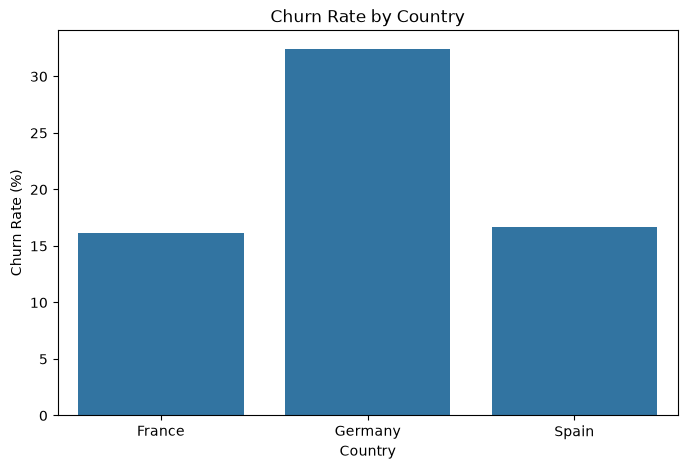

In [19]:
# Visualize churn rate by country
plt.figure(figsize=(8, 5))

sns.barplot(
    data=country_analysis,
    x="country",
    y="churn_rate"
)

plt.title("Churn Rate by Country")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")

plt.show()

#### Insight

- Germany has a noticeably higher churn rate compared to France and Spain.
- France and Spain have relatively similar churn rates.
- Customer count should also be considered when evaluating the higher churn rate in Germany.

### Age Analysis

In [20]:
# Check summary statistics of customer ages
df["age"].describe()

count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: age, dtype: float64

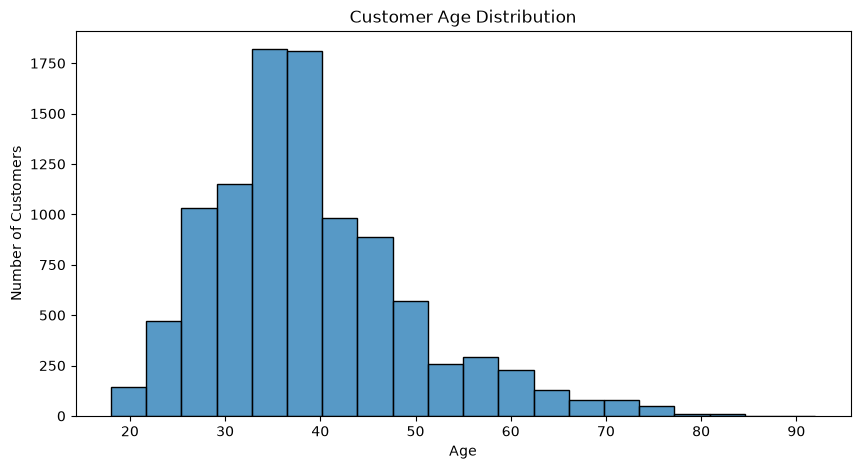

In [21]:
# Visualize the distribution of customer ages
plt.figure(figsize=(10, 5))

sns.histplot(df["age"], bins=20)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

In [22]:
# Create age groups for customer segmentation
bins = [17, 30, 40, 50, 60, np.inf]

labels = [
    "18-30",
    "31-40",
    "41-50",
    "51-60",
    "61+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels
)

In [23]:
# Count customers in each age group
df["age_group"].value_counts().sort_index()

age_group
18-30    1968
31-40    4451
41-50    2320
51-60     797
61+       464
Name: count, dtype: int64

In [24]:
# Analyze customer churn by age group
age_analysis = (
    df.groupby("age_group", observed=True)
      .agg(
          customer_count=("customer_id", "count"),
          churned_customers=("churn", "sum"),
          churn_rate=("churn", "mean")
      )
      .reset_index()
)

# Convert churn rate to percentage
age_analysis["churn_rate"] = (
    age_analysis["churn_rate"] * 100
).round(2)

age_analysis

,age_group,customer_count,churned_customers,churn_rate
0,18-30,1968,148,7.52
1,31-40,4451,538,12.09
2,41-50,2320,788,33.97
3,51-60,797,448,56.21
4,61+,464,115,24.78


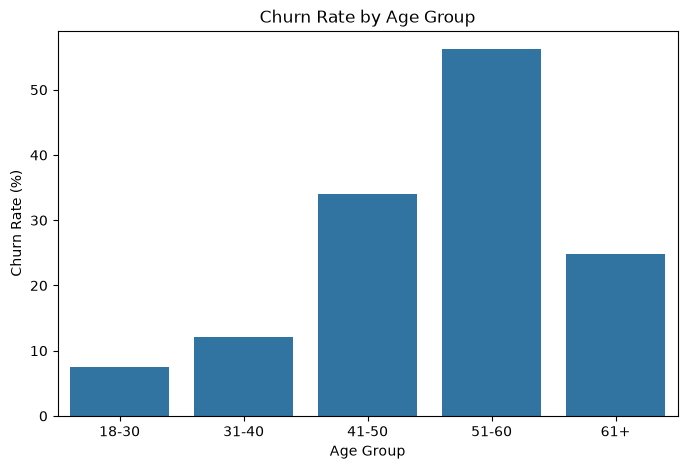

In [25]:
# Visualize churn rate by age group
plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_analysis,
    x="age_group",
    y="churn_rate"
)

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")

plt.show()

#### Insight

- The 51-60 age group has the highest churn rate.
- More than half of the customers in this age group have churned.
- Unlike some small balance segments with high churn rates, this age group contains a larger number of customers (797).
- Age appears to be an important factor to examine in the churn analysis.

### Active Member Analysis

In [26]:
# Analyze customer churn by active member status
active_member_analysis = (
    df.groupby("active_member")
      .agg(
          customer_count=("customer_id", "count"),
          churned_customers=("churn", "sum"),
          churn_rate=("churn", "mean")
      )
      .reset_index()
)

# Convert churn rate to percentage
active_member_analysis["churn_rate"] = (
    active_member_analysis["churn_rate"] * 100
).round(2)

active_member_analysis

,active_member,customer_count,churned_customers,churn_rate
0,0,4849,1302,26.85
1,1,5151,735,14.27


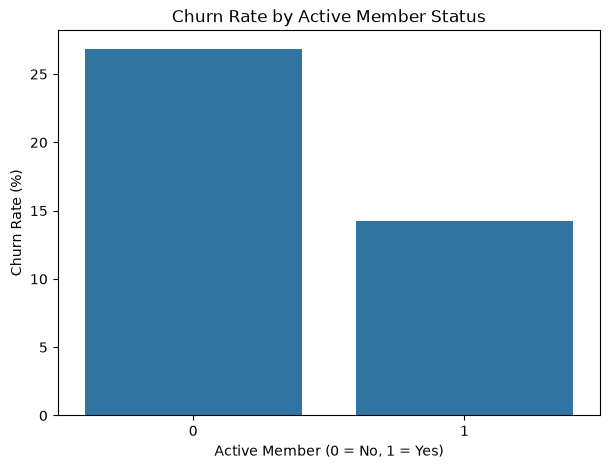

In [27]:
# Visualize churn rate by active member status
plt.figure(figsize=(7, 5))

sns.barplot(
    data=active_member_analysis,
    x="active_member",
    y="churn_rate"
)

plt.title("Churn Rate by Active Member Status")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.show()

#### Insight

- Inactive customers have a noticeably higher churn rate than active customers.
- The churn rate of inactive customers is almost twice as high as that of active customers.
- Customer activity appears to be an important factor associated with churn.

### Products Number Analysis

In [28]:
# Check the number of customers by products number
df["products_number"].value_counts().sort_index()

products_number
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [29]:
# Analyze customer churn by number of products
products_analysis = (
    df.groupby("products_number")
      .agg(
          customer_count=("customer_id", "count"),
          churned_customers=("churn", "sum"),
          churn_rate=("churn", "mean")
      )
      .reset_index()
)

# Convert churn rate to percentage
products_analysis["churn_rate"] = (
    products_analysis["churn_rate"] * 100
).round(2)

products_analysis

,products_number,customer_count,churned_customers,churn_rate
0,1,5084,1409,27.71
1,2,4590,348,7.58
2,3,266,220,82.71
3,4,60,60,100.00


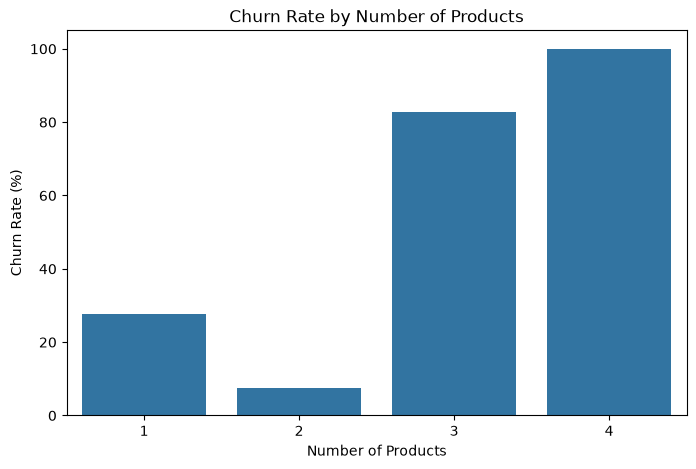

In [30]:
# Visualize churn rate by number of products
plt.figure(figsize=(8, 5))

sns.barplot(
    data=products_analysis,
    x="products_number",
    y="churn_rate"
)

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.show()

#### Insight

- Customers with 4 products have a 100% churn rate, but this group contains only 60 customers.
- Customers with 3 products also have a very high churn rate (82.71%).
- Customers with 2 products have the lowest churn rate (7.58%).
- Churn increases sharply among customers with 3 or 4 products.

## Export Data for Power BI

The analyzed dataset is exported with the newly created balance and age segments for dashboard development.

In [31]:
# Export the prepared dataset for Power BI
df.to_csv(
    "../data/customer_churn_cleaned.csv",
    index=False
)

print("Dataset exported successfully.")

Dataset exported successfully.


In [32]:
# Export analysis tables
balance_analysis.to_csv("../outputs/balance_analysis.csv", index=False)
country_analysis.to_csv("../outputs/country_analysis.csv", index=False)
age_analysis.to_csv("../outputs/age_analysis.csv", index=False)
active_member_analysis.to_csv("../outputs/active_member_analysis.csv", index=False)
products_analysis.to_csv("../outputs/products_analysis.csv", index=False)

print("Analysis tables exported successfully.")

Analysis tables exported successfully.


## 6. Customer Risk Segmentation

The purpose of this section is to identify customer segments
with both a high churn rate and meaningful customer volume.

The analysis focuses on:
- Country
- Age group
- Activity status
- Number of products
- Balance range

In [33]:
# Customer Risk Segmentation
# Analyze churn across combinations of customer characteristics

segment_analysis = (
    df.groupby(
        ["country", "age_group", "active_member", "products_number"],
        observed=True
    )
    .agg(
        customer_count=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
)

# Convert churn rate to percentage
segment_analysis["churn_rate"] = (
    segment_analysis["churn_rate"] * 100
).round(2)

segment_analysis.head(10)

,country,age_group,active_member,products_number,customer_count,churned_customers,churn_rate
0,France,18-30,0,1,234,24,10.26
1,France,18-30,0,2,270,3,1.11
2,France,18-30,0,3,6,4,66.67
3,France,18-30,1,1,237,11,4.64
4,France,18-30,1,2,286,8,2.80
5,France,18-30,1,3,5,1,20.00
6,France,31-40,0,1,583,93,15.95
7,France,31-40,0,2,578,31,5.36
8,France,31-40,0,3,16,13,81.25
9,France,31-40,0,4,3,3,100.00


In [34]:
# Keep segments with at least 50 customers
meaningful_segments = segment_analysis[
    segment_analysis["customer_count"] >= 50
].copy()

# Sort by highest churn rate
high_risk_segments = meaningful_segments.sort_values(
    by="churn_rate",
    ascending=False
)

high_risk_segments.head(15)

,country,age_group,active_member,products_number,customer_count,churned_customers,churn_rate
60,Germany,51-60,0,1,90,82,91.11
22,France,51-60,0,1,111,97,87.39
52,Germany,41-50,0,1,233,161,69.10
64,Germany,51-60,1,1,70,39,55.71
56,Germany,41-50,1,1,154,80,51.95
88,Spain,41-50,0,1,162,78,48.15
14,France,41-50,0,1,301,135,44.85
26,France,51-60,1,1,122,47,38.52
100,Spain,51-60,1,1,71,23,32.39
44,Germany,31-40,0,1,260,84,32.31


In [35]:
# Calculate segment impact
high_risk_segments["segment_impact"] = (
    high_risk_segments["customer_count"]
    * high_risk_segments["churn_rate"] / 100
).round(0)

# Sort segments by number of churned customers
impact_segments = high_risk_segments.sort_values(
    by="churned_customers",
    ascending=False
)

impact_segments.head(15)

,country,age_group,active_member,products_number,customer_count,churned_customers,churn_rate,segment_impact
52,Germany,41-50,0,1,233,161,69.10,161.0
14,France,41-50,0,1,301,135,44.85,135.0
22,France,51-60,0,1,111,97,87.39,97.0
6,France,31-40,0,1,583,93,15.95,93.0
44,Germany,31-40,0,1,260,84,32.31,84.0
60,Germany,51-60,0,1,90,82,91.11,82.0
56,Germany,41-50,1,1,154,80,51.95,80.0
88,Spain,41-50,0,1,162,78,48.15,78.0
18,France,41-50,1,1,255,71,27.84,71.0
48,Germany,31-40,1,1,242,60,24.79,60.0


In [36]:
# Identify potentially at-risk customers who have not churned yet

at_risk_customers = df[
    (df["churn"] == 0) &
    (df["active_member"] == 0) &
    (df["products_number"] == 1) &
    (df["age_group"].isin(["41-50", "51-60"]))
].copy()

print("Potential At-Risk Customers:", len(at_risk_customers))

at_risk_customers[
    [
        "customer_id",
        "country",
        "age",
        "age_group",
        "balance",
        "products_number",
        "active_member"
    ]
].head(10)

Potential At-Risk Customers: 349


,customer_id,country,age,age_group,balance,products_number,active_member
18,15661507,Spain,45,41-50,0.00,1,0
56,15630053,France,45,41-50,127864.40,1,0
112,15715951,France,42,41-50,100238.35,1,0
140,15698932,Germany,44,41-50,137452.09,1,0
148,15703264,France,44,41-50,120681.63,1,0
162,15630910,France,49,41-50,108007.36,1,0
167,15588537,Spain,41,41-50,109013.23,1,0
216,15680920,France,46,41-50,49512.55,1,0
261,15673481,Spain,48,41-50,99906.19,1,0
313,15797960,Germany,59,51-60,135296.33,1,0


In [37]:
# Business impact of potentially at-risk customers

at_risk_summary = (
    at_risk_customers
    .groupby("country")
    .agg(
        at_risk_customers=("customer_id", "count"),
        total_balance=("balance", "sum"),
        average_balance=("balance", "mean")
    )
    .reset_index()
)

at_risk_summary["total_balance"] = (
    at_risk_summary["total_balance"].round(2)
)

at_risk_summary["average_balance"] = (
    at_risk_summary["average_balance"].round(2)
)

at_risk_summary

,country,at_risk_customers,total_balance,average_balance
0,France,180,17504428.03,97246.82
1,Germany,80,9573876.95,119673.46
2,Spain,89,8290111.88,93147.32


In [38]:
# Create interpretable risk indicators

df["risk_inactive"] = (df["active_member"] == 0).astype(int)

df["risk_age"] = (
    df["age_group"].isin(["41-50", "51-60"])
).astype(int)

df["risk_one_product"] = (
    df["products_number"] == 1
).astype(int)

df[
    [
        "customer_id",
        "country",
        "age_group",
        "active_member",
        "products_number",
        "risk_inactive",
        "risk_age",
        "risk_one_product"
    ]
].head(10)

,customer_id,country,age_group,active_member,products_number,risk_inactive,risk_age,risk_one_product
0,15634602,France,41-50,1,1,0,1,1
1,15647311,Spain,41-50,1,1,0,1,1
2,15619304,France,41-50,0,3,1,1,0
3,15701354,France,31-40,0,2,1,0,0
4,15737888,Spain,41-50,1,1,0,1,1
5,15574012,Spain,41-50,0,2,1,1,0
6,15592531,France,41-50,1,2,0,1,0
7,15656148,Germany,18-30,0,4,1,0,0
8,15792365,France,41-50,1,2,0,1,0
9,15592389,France,18-30,1,1,0,0,1


In [39]:
# Calculate the number of risk indicators for each customer

df["risk_factor_count"] = (
    df["risk_inactive"]
    + df["risk_age"]
    + df["risk_one_product"]
)

# Analyze actual churn by number of risk factors
risk_validation = (
    df.groupby("risk_factor_count")
    .agg(
        customer_count=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
    .reset_index()
)

risk_validation["churn_rate"] = (
    risk_validation["churn_rate"] * 100
).round(2)

risk_validation

,risk_factor_count,customer_count,churned_customers,churn_rate
0,0,1847,96,5.20
1,1,4189,519,12.39
2,2,3031,838,27.65
3,3,933,584,62.59


In [40]:
# Create rule-based customer risk segments

def assign_risk_segment(risk_count):
    if risk_count == 0:
        return "Low Risk"
    elif risk_count == 1:
        return "Moderate Risk"
    elif risk_count == 2:
        return "High Risk"
    else:
        return "Critical Risk"

df["risk_segment"] = df["risk_factor_count"].apply(assign_risk_segment)

risk_segment_summary = (
    df.groupby("risk_segment")
    .agg(
        customer_count=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean"),
        total_balance=("balance", "sum"),
        average_balance=("balance", "mean")
    )
    .reset_index()
)

risk_segment_summary["churn_rate"] = (
    risk_segment_summary["churn_rate"] * 100
).round(2)

risk_segment_summary["total_balance"] = (
    risk_segment_summary["total_balance"].round(2)
)

risk_segment_summary["average_balance"] = (
    risk_segment_summary["average_balance"].round(2)
)

risk_segment_summary

,risk_segment,customer_count,churned_customers,churn_rate,total_balance,average_balance
0,Critical Risk,933,584,62.59,8.871104e+07,95081.50
1,High Risk,3031,838,27.65,2.783986e+08,91850.40
2,Low Risk,1847,96,5.20,9.637963e+07,52181.72
3,Moderate Risk,4189,519,12.39,3.013697e+08,71943.10


In [41]:
# Identify current customers in High and Critical Risk segments

retention_opportunity = df[
    (df["churn"] == 0) &
    (df["risk_segment"].isin(["High Risk", "Critical Risk"]))
].copy()

retention_summary = (
    retention_opportunity
    .groupby("risk_segment")
    .agg(
        customers=("customer_id", "count"),
        total_balance=("balance", "sum"),
        average_balance=("balance", "mean")
    )
    .reset_index()
)

retention_summary["total_balance"] = (
    retention_summary["total_balance"].round(2)
)

retention_summary["average_balance"] = (
    retention_summary["average_balance"].round(2)
)

retention_summary

,risk_segment,customers,total_balance,average_balance
0,Critical Risk,349,3.536842e+07,101342.17
1,High Risk,2193,2.020838e+08,92149.49


In [42]:
# Compare churn rates for each individual risk factor

risk_factor_analysis = []

for factor in ["risk_inactive", "risk_age", "risk_one_product"]:
    
    summary = (
        df.groupby(factor)
        .agg(
            customer_count=("customer_id", "count"),
            churned_customers=("churn", "sum"),
            churn_rate=("churn", "mean")
        )
        .reset_index()
    )
    
    summary["churn_rate"] = (
        summary["churn_rate"] * 100
    ).round(2)
    
    summary["risk_factor"] = factor
    
    risk_factor_analysis.append(summary)

risk_factor_analysis = pd.concat(
    risk_factor_analysis,
    ignore_index=True
)

risk_factor_analysis

,risk_inactive,customer_count,churned_customers,churn_rate,risk_factor,risk_age,risk_one_product
0,0.0,5151,735,14.27,risk_inactive,NaN,NaN
1,1.0,4849,1302,26.85,risk_inactive,NaN,NaN
2,NaN,6883,801,11.64,risk_age,0.0,NaN
3,NaN,3117,1236,39.65,risk_age,1.0,NaN
4,NaN,4916,628,12.77,risk_one_product,NaN,0.0
5,NaN,5084,1409,27.71,risk_one_product,NaN,1.0


## 7. Churn Driver Analysis

In [43]:
# Check available columns before churn driver analysis

df.columns.tolist()

['customer_id',
 'credit_score',
 'country',
 'gender',
 'age',
 'tenure',
 'balance',
 'products_number',
 'credit_card',
 'active_member',
 'estimated_salary',
 'churn',
 'balance_range',
 'age_group',
 'risk_inactive',
 'risk_age',
 'risk_one_product',
 'risk_factor_count',
 'risk_segment']

In [44]:
# Select original customer features for churn driver analysis

features = [
    "credit_score",
    "country",
    "gender",
    "age",
    "tenure",
    "balance",
    "products_number",
    "credit_card",
    "active_member",
    "estimated_salary"
]

X = df[features].copy()
y = df["churn"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Feature matrix shape: (10000, 10)
Target shape: (10000,)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [45]:
# Prepare numerical and categorical features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_features = [
    "credit_score",
    "age",
    "tenure",
    "balance",
    "products_number",
    "credit_card",
    "active_member",
    "estimated_salary"
]

categorical_features = [
    "country",
    "gender"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features)
    ]
)

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary']
Categorical features: ['country', 'gender']


In [46]:
# Split data into training and test sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", X_train.shape[0])
print("Test customers:", X_test.shape[0])

print("\nTraining churn rate:")
print((y_train.mean() * 100).round(2))

print("\nTest churn rate:")
print((y_test.mean() * 100).round(2))

Training customers: 8000
Test customers: 2000

Training churn rate:
20.38

Test churn rate:
20.35


In [47]:
# Build and train Logistic Regression model

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [48]:
# Evaluate Logistic Regression model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Make predictions on test data
y_pred = logistic_model.predict(X_test)

# Probability of churn
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 Score:  {f1:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy:  0.808
Precision: 0.589
Recall:    0.187
F1 Score:  0.284
ROC-AUC:   0.775

Confusion Matrix:
[[1540   53]
 [ 331   76]]


In [49]:
# Compare different probability thresholds

import pandas as pd

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    
    y_pred_threshold = (y_prob >= threshold).astype(int)
    
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_threshold),
        "recall": recall_score(y_test, y_pred_threshold),
        "f1_score": f1_score(y_test, y_pred_threshold)
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results[["precision", "recall", "f1_score"]] = (
    threshold_results[["precision", "recall", "f1_score"]] * 100
).round(2)

threshold_results

,threshold,precision,recall,f1_score
0,0.20,37.61,71.99,49.41
1,0.25,43.06,60.20,50.20
2,0.30,48.50,51.60,50.00
3,0.35,51.52,41.52,45.99
4,0.40,53.14,31.20,39.32
5,0.45,54.01,24.82,34.01
6,0.50,58.91,18.67,28.36


In [50]:
# Extract Logistic Regression coefficients

feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = logistic_model.named_steps[
    "classifier"
].coef_[0]

driver_analysis = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

driver_analysis["abs_coefficient"] = (
    driver_analysis["coefficient"].abs()
)

driver_analysis = driver_analysis.sort_values(
    "abs_coefficient",
    ascending=False
)

driver_analysis

,feature,coefficient,abs_coefficient
8,cat__country_Germany,0.819952,0.819952
1,num__age,0.738520,0.738520
10,cat__gender_Male,-0.522198,0.522198
6,num__active_member,-0.515739,0.515739
3,num__balance,0.161558,0.161558
0,num__credit_score,-0.085954,0.085954
4,num__products_number,-0.070655,0.070655
7,num__estimated_salary,0.047797,0.047797
9,cat__country_Spain,0.043700,0.043700
5,num__credit_card,-0.032120,0.032120


In [51]:
# Generate churn probability for all customers

df["churn_probability"] = (
    logistic_model.predict_proba(X)[:, 1] * 100
).round(2)

df[
    [
        "customer_id",
        "country",
        "age",
        "active_member",
        "products_number",
        "churn",
        "churn_probability"
    ]
].sort_values(
    "churn_probability",
    ascending=False
).head(10)

,customer_id,country,age,active_member,products_number,churn,churn_probability
3531,15653251,France,84,0,1,1,92.62
4815,15737647,Germany,77,0,1,0,92.22
9587,15653050,Germany,76,0,1,0,91.95
7499,15790113,Germany,71,0,1,1,90.04
9555,15655360,Germany,72,0,1,1,89.36
7629,15591107,Germany,68,0,1,1,88.09
8488,15794360,Germany,70,0,2,1,87.23
9747,15775761,Germany,69,0,3,1,86.93
8156,15785576,Germany,71,0,1,0,86.35
7008,15638610,Germany,65,0,1,1,85.99


In [52]:
# Create model-based churn risk levels

def assign_model_risk(probability):
    if probability < 25:
        return "Low Risk"
    elif probability < 50:
        return "Moderate Risk"
    elif probability < 75:
        return "High Risk"
    else:
        return "Critical Risk"

df["model_risk_level"] = df["churn_probability"].apply(assign_model_risk)

risk_level_summary = (
    df.groupby("model_risk_level")
    .agg(
        customer_count=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        average_churn_probability=("churn_probability", "mean"),
        actual_churn_rate=("churn", "mean")
    )
    .reset_index()
)

risk_level_summary["average_churn_probability"] = (
    risk_level_summary["average_churn_probability"].round(2)
)

risk_level_summary["actual_churn_rate"] = (
    risk_level_summary["actual_churn_rate"] * 100
).round(2)

risk_level_summary

,model_risk_level,customer_count,churned_customers,average_churn_probability,actual_churn_rate
0,Critical Risk,76,52,80.63,68.42
1,High Risk,636,373,59.18,58.65
2,Low Risk,7140,819,11.91,11.47
3,Moderate Risk,2148,793,34.82,36.92


In [53]:
# Export final dataset for Power BI

powerbi_df = df[
    [
        "customer_id",
        "credit_score",
        "country",
        "gender",
        "age",
        "tenure",
        "balance",
        "products_number",
        "credit_card",
        "active_member",
        "estimated_salary",
        "churn",
        "balance_range",
        "age_group",
        "risk_inactive",
        "risk_age",
        "risk_one_product",
        "risk_factor_count",
        "risk_segment",
        "churn_probability",
        "model_risk_level"
    ]
].copy()

powerbi_df.to_csv(
    "../data/customer_churn_powerbi.csv",
    index=False
)

print("Power BI dataset exported successfully.")
print("Rows:", powerbi_df.shape[0])
print("Columns:", powerbi_df.shape[1])

Power BI dataset exported successfully.
Rows: 10000
Columns: 21


In [54]:
import pandas as pd

probability_bins = pd.cut(
    df["churn_probability"],
    bins=[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    include_lowest=True
)

probability_analysis = (
    df.groupby(probability_bins, observed=False)
      .agg(
          customer_count=("customer_id", "count"),
          churned_customers=("churn", "sum"),
          actual_churn_rate=("churn", "mean")
      )
      .reset_index()
)

probability_analysis["actual_churn_rate"] *= 100

probability_analysis

,churn_probability,customer_count,churned_customers,actual_churn_rate
0,"(-0.001, 10.0]",3160,190,6.012658
1,"(10.0, 20.0]",3002,417,13.890740
2,"(20.0, 30.0]",1675,408,24.358209
3,"(30.0, 40.0]",906,352,38.852097
4,"(40.0, 50.0]",545,245,44.954128
5,"(50.0, 60.0]",379,197,51.978892
6,"(60.0, 70.0]",211,141,66.824645
7,"(70.0, 80.0]",88,67,76.136364
8,"(80.0, 90.0]",30,18,60.000000
9,"(90.0, 100.0]",4,2,50.000000
